In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("Desktop/DNPROJECT/sales.csv")

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order_ID"].nunique()
total_quantity = df["Quantity"].sum()

profit_margin = (
    total_profit / total_sales * 100
    if total_sales != 0 else 0
)

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Orders:", total_orders)
print("Total Quantity:", total_quantity)
print("Profit Margin:", round(profit_margin, 2), "%")

# pd.read_csv() loads the sales dataset.



# .sum() calculates sales, profit, and quantity totals.



# .nunique() counts distinct order IDs.



# np is imported for numerical operations,it can also be used for calculations such as np.where() and np.select().



# round() formats the displayed results.

Total Sales: 25158991.27
Total Profit: 3069331.75
Total Orders: 5000
Total Quantity: 27141
Profit Margin: 12.2 %


In [3]:
import pandas as pd

df = pd.read_csv("Desktop/DNPROJECT/sales.csv")

# Check dataset
print(df.head())
print(df.info())
print(df.isnull().sum())

# Remove duplicate records
df = df.drop_duplicates()

# Convert date column
df["Order_Date"] = pd.to_datetime(
    df["Order_Date"], errors="coerce"
)

# Convert numerical columns
for col in ["Sales", "Profit", "Quantity"]:
    df[col] = pd.to_numeric(
        df[col], errors="coerce"
    )

# Remove records with invalid essential values
df = df.dropna(
    subset=["Order_ID", "Order_Date", "Sales", "Profit"]
)

# Extract month
df["Month"] = df["Order_Date"].dt.to_period("M").astype(str)

# Sales by category
category_sales = df.groupby(
    "Category"
)["Sales"].sum().sort_values(ascending=False)

print(category_sales)

# "I used Pandas to inspect the dataset, handle duplicate records, convert dates and numeric columns, manage missing values in essential fields,
 # and aggregate sales by category. This helped prepare reliable data for KPI calculations and visualizations."

   Order_ID  Order_Date   Ship_Date  Year      Month Quarter Customer_ID  \
0  ORD00001  2023-05-23  2023-05-29  2023        May      Q2    CUST2680   
1  ORD00002  2024-09-08  2024-09-09  2024  September      Q3    CUST4258   
2  ORD00003  2023-10-12  2023-10-14  2023    October      Q4    CUST4528   
3  ORD00004  2024-07-03  2024-07-04  2024       July      Q3    CUST7202   
4  ORD00005  2023-10-24  2023-10-25  2023    October      Q4    CUST4815   

  Customer_Name      Segment Country  ... Sub_Category Product_Name    Sales  \
0        Shweta     Consumer   India  ...         Sofa         Sofa  3870.49   
1        Shweta    Corporate   India  ...        Table        Table  7373.54   
2         Vikas     Consumer   India  ...        Table        Table  1728.98   
3          Neha  Home Office   India  ...     Keyboard     Keyboard   769.22   
4         Priya    Corporate   India  ...     Notebook     Notebook  6090.93   

  Quantity Discount   Profit  Delivery_Days  Profit_Margin  Pa

In [12]:
import numpy as np

df["Performance"] = np.where(
    df["Profit"] > 450,
    "Profitable",
    "Loss or Break-even"
)

print(df[["Sales", "Profit", "Performance"]].head())

# Another useful example is calculating profit margin safely.

# df["Profit_Margin"] = np.divide(
#     df["Profit"] * 100,
#     df["Sales"],
#     out=np.zeros(len(df), dtype=float),
#     where=df["Sales"].to_numpy() != 0
# )

# "I used NumPy for numerical operations and conditional calculations, such as classifying transactions based on profit and
# calculating row-level profit margins safely."


     Sales   Profit         Performance
0  3870.49  1094.38          Profitable
1  7373.54  1176.30          Profitable
2  1728.98     7.95  Loss or Break-even
3   769.22   194.74  Loss or Break-even
4  6090.93  1204.94          Profitable


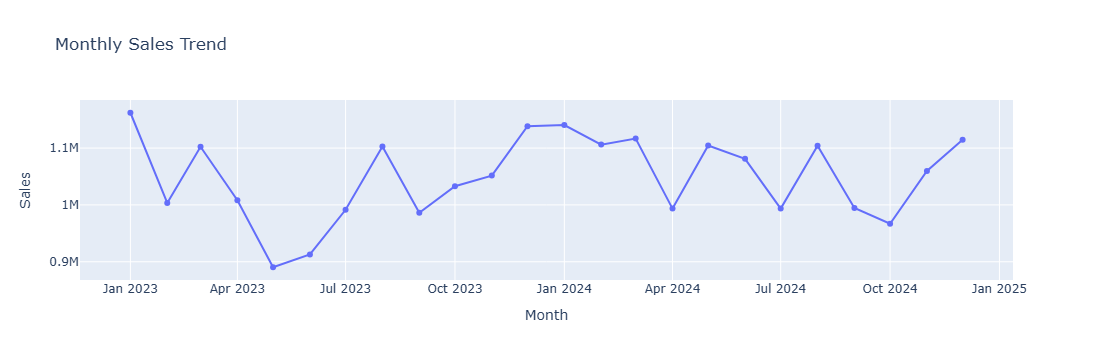

In [15]:
# Monthly sales trend

import plotly.express as px

monthly_sales = (
    df.groupby("Month", as_index=False)["Sales"]
      .sum()
      .sort_values("Month")
)

fig = px.line(
    monthly_sales,
    x="Month",
    y="Sales",
    title="Monthly Sales Trend",
    markers=True
)

fig.show()

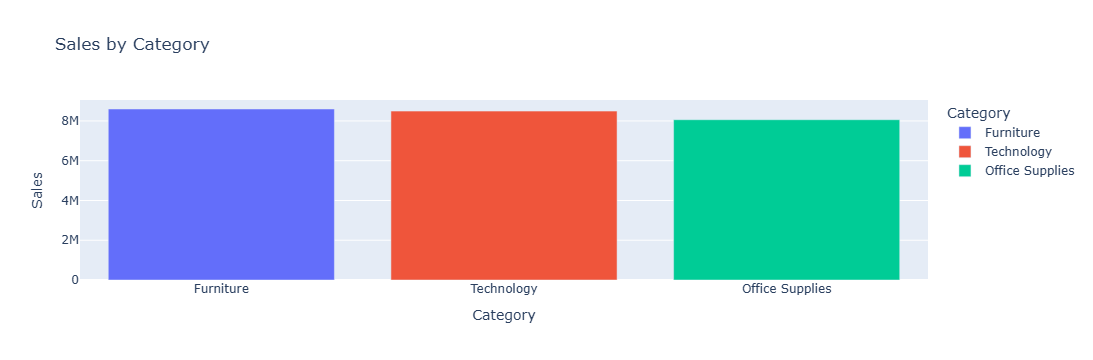

In [16]:
# Sales by category

category_sales = (
    df.groupby("Category", as_index=False)["Sales"]
      .sum()
      .sort_values("Sales", ascending=False)
)

fig = px.bar(
    category_sales,
    x="Category",
    y="Sales",
    title="Sales by Category",
    color="Category"
)

fig.show()

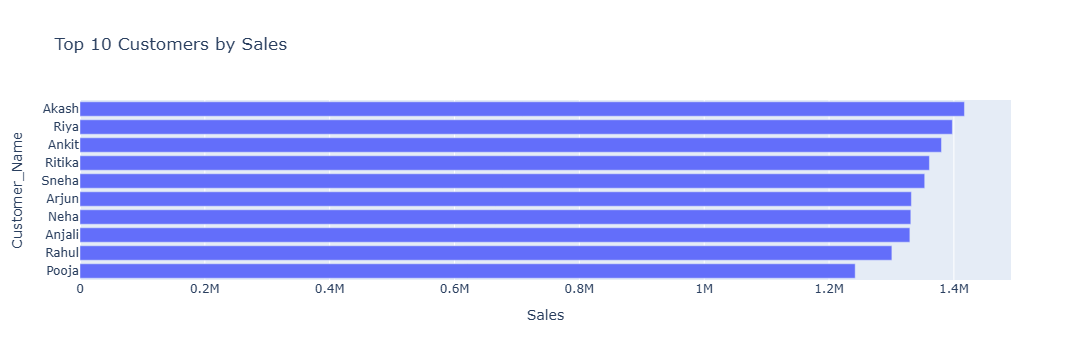

In [19]:
# Top 10 customers

top_customers = (
    df.groupby("Customer_Name", as_index=False)["Sales"]
      .sum()
      .nlargest(10, "Sales")
      .sort_values("Sales")
)

fig = px.bar(
    top_customers,
    x="Sales",
    y="Customer_Name",
    orientation="h",
    title="Top 10 Customers by Sales"
)

fig.show()

# "I used Plotly Express to create interactive visualizations for monthly sales trends, category performance, and top customers. 
# These charts help users compare performance and identify business trends."